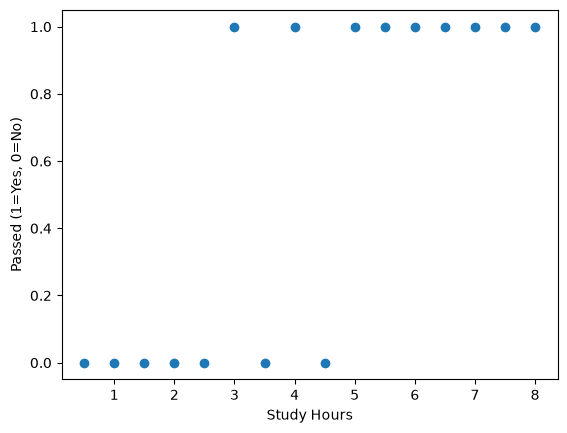

Test Accuracy: 0.75
Predictions: [0 0]
Probabilities:
[[0.54248654 0.45751346]
 [0.9310934  0.0689066 ]]


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

# (a) Load data and scatter plot
df = pd.DataFrame({
    'hours': [0.5,1,1.5,2,2.5,3,3.5,4,4.5,5,5.5,6,6.5,7,7.5,8],
    'passed': [0,0,0,0,0,1,0,1,0,1,1,1,1,1,1,1]
})
plt.scatter(df['hours'], df['passed'])
plt.xlabel('Study Hours')
plt.ylabel('Passed (1=Yes, 0=No)')
plt.show()

# (b) Split data
X = df[['hours']]
y = df['passed']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# (c) Train model and score
model = LogisticRegression()
model.fit(X_train, y_train)
print(f"Test Accuracy: {model.score(X_test, y_test)}")

# (d) Predictions and Probabilities
X_new = pd.DataFrame({'hours': [4, 2]})
preds = model.predict(X_new)
probs = model.predict_proba(X_new)
print(f"Predictions: {preds}")
print(f"Probabilities:\n{probs}")

X shape: (1797, 64), y shape: (1797,)


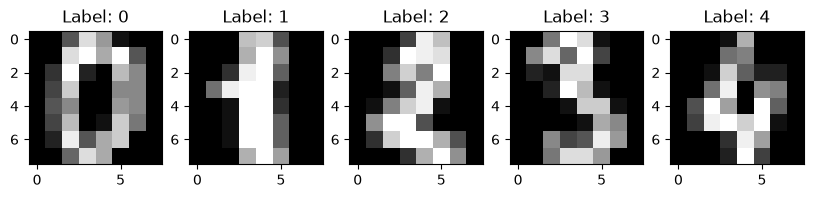

Accuracy with K=3: 0.9833333333333333


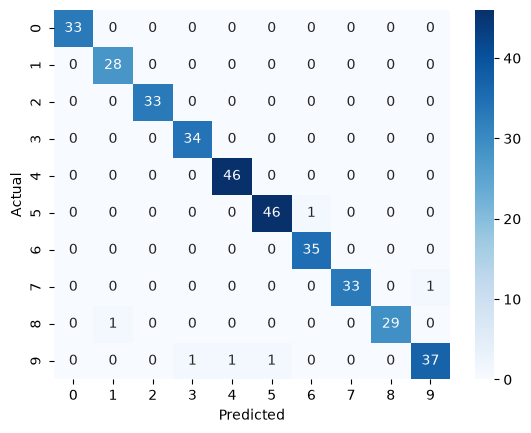

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        33
           1       0.97      1.00      0.98        28
           2       1.00      1.00      1.00        33
           3       0.97      1.00      0.99        34
           4       0.98      1.00      0.99        46
           5       0.98      0.98      0.98        47
           6       0.97      1.00      0.99        35
           7       1.00      0.97      0.99        34
           8       1.00      0.97      0.98        30
           9       0.97      0.93      0.95        40

    accuracy                           0.98       360
   macro avg       0.98      0.98      0.98       360
weighted avg       0.98      0.98      0.98       360

Best K: 1
Best Score: 0.9860820751064654


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, classification_report

# (a) Load dataset
digits = load_digits()
X, y = digits.data, digits.target
print(f"X shape: {X.shape}, y shape: {y.shape}")

fig, axes = plt.subplots(1, 5, figsize=(10, 3))
for i in range(5):
    axes[i].imshow(digits.images[i], cmap='gray')
    axes[i].set_title(f"Label: {y[i]}")
plt.show()

# (b) Split and train (K=3)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)
print(f"Accuracy with K=3: {knn.score(X_test, y_test)}")

# (c) Confusion matrix and report
y_pred = knn.predict(X_test)
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()
print(classification_report(y_test, y_pred))

# (d) GridSearchCV for best K
param_grid = {'n_neighbors': range(1, 21)}
grid = GridSearchCV(KNeighborsClassifier(), param_grid, cv=5)
grid.fit(X_train, y_train)
print(f"Best K: {grid.best_params_['n_neighbors']}")
print(f"Best Score: {grid.best_score_}")

In [4]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline
from sklearn.metrics import confusion_matrix

messages = [
    "Win a free prize now, claim your free entry",
    "Congratulations winner, free message waiting for you",
    "Free entry in our weekly draw, text now",
    "Urgent, you have won cash, call now",
    "Claim your free reward today winner",
    "Are we still meeting for the project review tomorrow",
    "Please send me the assignment notes when you are free",
    "Thanks for the update, I will push the code to GitHub tonight",
    "Can you share the dataset for the module six exercise",
    "Lunch at one, let me know if you can join",
    "Reminder, the internship meeting is at five today",
    "Good work on your report, please add the confusion matrix"
]
labels = ["spam", "spam", "spam", "spam", "spam", "ham", "ham", "ham", "ham", "ham", "ham", "ham"]

# (a) DataFrame setup
df = pd.DataFrame({'text': messages, 'label': labels})
df['spam'] = df['label'].apply(lambda x: 1 if x == 'spam' else 0)
print(df['spam'].value_counts())

# (b) Split
X_train, X_test, y_train, y_test = train_test_split(df['text'], df['spam'], test_size=0.25, stratify=df['spam'], random_state=42)

# (c) Pipeline
pipeline = make_pipeline(CountVectorizer(), MultinomialNB())
pipeline.fit(X_train, y_train)
print(f"Test Accuracy: {pipeline.score(X_test, y_test)}")

# (d) New predictions
new_msgs = ["Free entry, claim your prize now", "Can we review the notebook tomorrow", "You are a winner, call now"]
print("Predictions for new messages:", pipeline.predict(new_msgs))

# (e) Confusion Matrix
print("Confusion Matrix:\n", confusion_matrix(y_test, pipeline.predict(X_test)))

spam
0    7
1    5
Name: count, dtype: int64
Test Accuracy: 1.0
Predictions for new messages: [1 0 1]
Confusion Matrix:
 [[2 0]
 [0 1]]


In [5]:
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

# (a) Load and explore
wine = load_wine()
df = pd.DataFrame(wine.data, columns=wine.feature_names)
df['target'] = wine.target
print(df.head())
print(df.describe())
print(df['target'].value_counts())

# (b) Split and train
X_train, X_test, y_train, y_test = train_test_split(df.drop('target', axis=1), df['target'], test_size=0.25, random_state=42)

gnb = GaussianNB()
gnb.fit(X_train, y_train)

mnb = MultinomialNB()
mnb.fit(X_train, y_train)

# (c) Evaluate
print(f"Gaussian Accuracy: {gnb.score(X_test, y_test)}")
print(classification_report(y_test, gnb.predict(X_test)))

print(f"Multinomial Accuracy: {mnb.score(X_test, y_test)}")
print(classification_report(y_test, mnb.predict(X_test)))

# (e) Bonus: Logistic Regression
lr = LogisticRegression(max_iter=10000)
lr.fit(X_train, y_train)
print(f"Logistic Regression Accuracy: {lr.score(X_test, y_test)}")

   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  target  
0          